# Lab 2: Probability, Distributions, and Statistical Questions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.integrate import trapezoid

## Problem 1
To set up the problem, assume in 1 day the average cosmic-ray background is some number X (pick someting btwn 0.5 and 10, with different values for you and your lab partner) and follows a Poisson Distribution; and the average number of gamma-rays emitted by your hypothetical source is Y (pick something larger than X).

#### A) Show how the probability distribution of the background changes as you integrate (sum) for more days.

In [2]:
# Set up day 1 cosmic background with ave background of 3.5
x1 = np.arange(0,20, 1)
day_1 = stats.poisson.pmf(x1, 3.5)

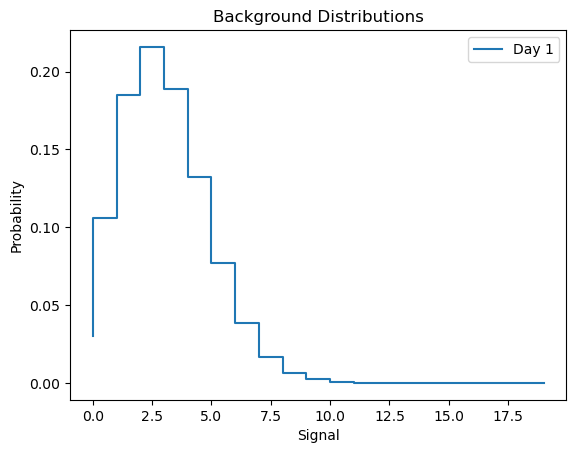

In [3]:
# Plot the initial day 1 background
fig, ax = plt.subplots()
ax.step(x1, day_1, label = 'Day 1')
ax.set_title('Background Distributions')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')
ax.legend()

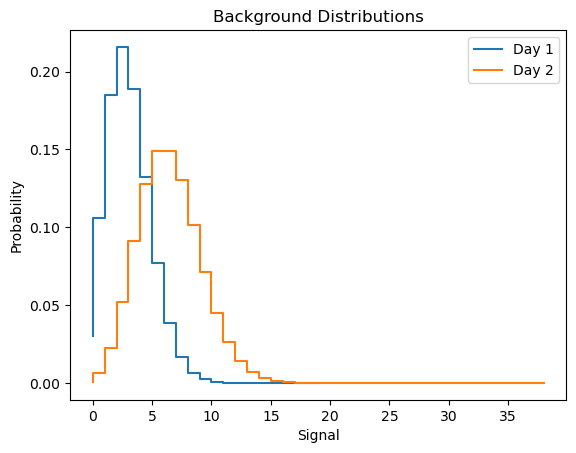

In [4]:
# Find the day 2bckgd
day_2 = np.convolve(day_1, day_1)
x2 = np.arange(0,39,1)

fig, ax = plt.subplots()
ax.step(x1, day_1, label = 'Day 1')
ax.step(x2, day_2, label = 'Day 2')
ax.set_title('Background Distributions')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')
ax.legend()

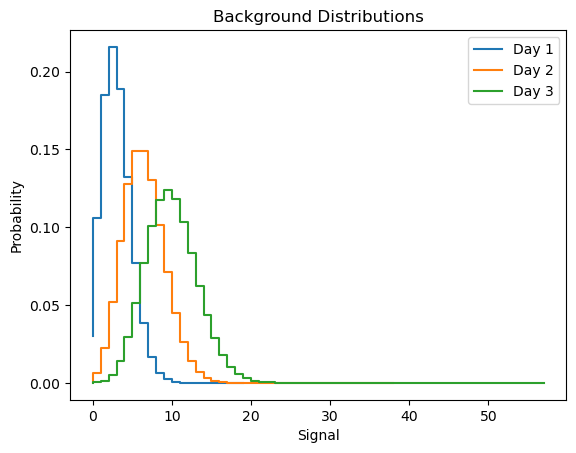

In [5]:
# Day 3
day_3 = np.convolve(day_2, day_1)
x3 = np.arange(0,58,1)

fig, ax = plt.subplots()
ax.step(x1, day_1, label = 'Day 1')
ax.step(x2, day_2, label = 'Day 2')
ax.step(x3, day_3, label = 'Day 3')
ax.set_title('Background Distributions')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')
ax.legend()

#### B) Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.

In [6]:
# Define function for sum after n days
def sum_dist(n, day_i = day_1, xi = x1):
    domain = len(xi)
    x_n = np.arange(0, n*domain - n+1, 1) 
    day_n = day_1
    for i in range(0,n-1):
        day_n = np.convolve(day_n, day_1)
    return x_n, day_n

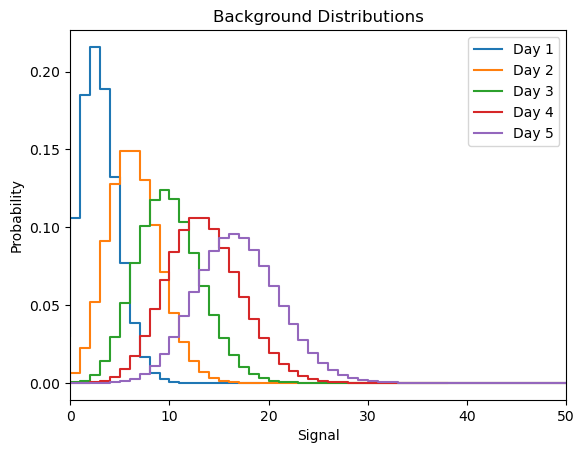

In [7]:
fig, ax = plt.subplots()
x4, day_4 = sum_dist(4)
x5,day_5 = sum_dist(5)
ax.set_xlim(0,50)
ax.step(x1, day_1, label = 'Day 1')
ax.step(x2, day_2, label = 'Day 2')
ax.step(x3, day_3, label = 'Day 3')
ax.step(x4, day_4, label = 'Day 4')
ax.step(x5, day_5, label = 'Day 5')

ax.set_title('Background Distributions')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')
ax.legend()

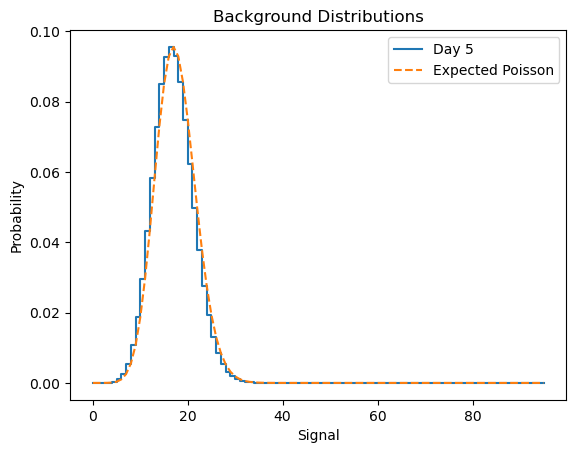

In [8]:
# 5 days
expected = stats.poisson.pmf(x5, 3.5*5)
fig, ax = plt.subplots()
ax.step(x5, day_5, label = 'Day 5')
ax.plot(x5, expected, label = 'Expected Poisson', linestyle = '--')

ax.set_title('Background Distributions')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')
ax.legend()

#### Explanation 

$$\mathcal P(k, \lambda) = \frac{\lambda^k e^{-\lambda}}{k!} $$

If you sum multiple Poisson distributions:

$$\sum_n \mathcal P_n = \frac{\lambda_1^{k_1} e^{-\lambda_1}}{k_1!} + \frac{\lambda_2^{k_2} e^{-\lambda_2}}{k_2!} + \dots $$

Considering just the first two terms with $n =k_1 + k_2$

$$\Rightarrow e^{\lambda_1 + \lambda_2}\sum_{k=0}^n \frac{\lambda_1^k\lambda_2^{(n-k)}}{k!(n-k)!} = e^{\lambda_1 + \lambda_2}\sum_{k=0}^n \binom{n}{k} \lambda_1^k\lambda_2^{(n-k)}$$

Substituting the Binomial Distribution:

$$\Rightarrow \mathcal{P}_{1+2} = \frac{e^{\lambda_1 + \lambda_2}(\lambda_1 + \lambda_2)^n}{n!}$$

This takes the form of a another Poisson distribution with the lambdas added together and the k values combined.

**Conceptually**

Multiple Poissons adding to a Poisson makes sense because each trial/day is independent, and so the random chances that observations occur over the same intervals are the same as adding the chances of observations and only considering a single interval. 

#### C) Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.

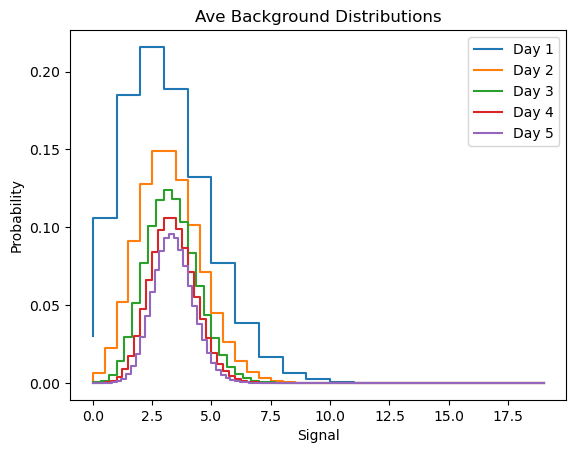

In [9]:
fig, ax = plt.subplots()
x4, day_4 = sum_dist(4)
x5,day_5 = sum_dist(5)
ax.step(x1, day_1, label = 'Day 1')
ax.step(x2/2, day_2, label = 'Day 2')
ax.step(x3/3, day_3, label = 'Day 3')
ax.step(x4/4, day_4, label = 'Day 4')
ax.step(x5/5, day_5, label = 'Day 5')

ax.set_title('Ave Background Distributions')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')
ax.legend()

**Part B**
After 5 days, the distribution is still Poisson, however when averaging the distribution you distort/squish it along the x-axis back into the original singal interval. This smooths out the differences on either side of the peak of the Poisson distribution. Additionally large $\lambda$ distributions can be approximated by large n Gaussians, so while remaining Poisson, it looks more and more like a Gaussian as each convolution increases $lambda$.

**Central Limit Theorem**

The central limit theorem says that over multiple averages any independent distribution will more and more closely approximate the standard normal distribution which is what we see in the above plot. 

#### D) Pick some number of days N, and assume you saw Y*N gamma rays from your source. Calculate the 'sigma' of your observation. [In reality the number of gamma-rays seen from a source will also fluctuate, but we're going to ignore that complication for a couple of labs.]

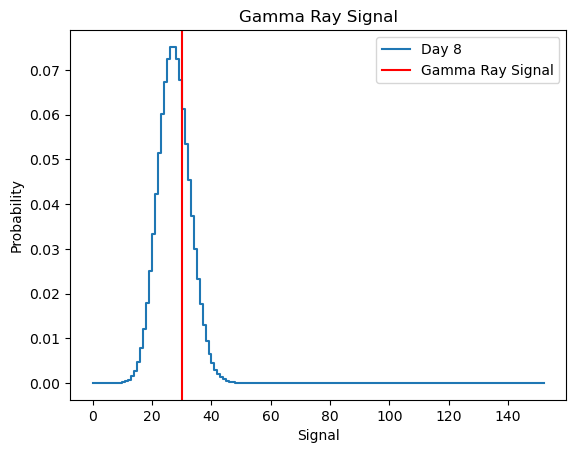

In [26]:
# Let N =8 days, Y= 30

x8, day_8 = sum_dist(8)
prob_Y = stats.poisson.sf(30, 3.5*8)
fig, ax = plt.subplots()
ax.step(x8, day_8, label = 'Day 8')
ax.axvline(30, color = 'red', label = 'Gamma Ray Signal')
ax.set_title('Gamma Ray Signal')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')
ax.legend()

In [27]:
sigma = stats.norm.isf(prob_Y)
print(f'The sigma of my observation is {sigma:.2f}, it is likely to be produced by the background')

The sigma of my observation is 0.50, it is likely to be produced by the background


## Problem 2
Pick a skewed continuous distribtuion, such as a Rayleigh, that describes your background over some observing interval.

#### A) Show how the distribution changes as you average over more observing intervals.

In [28]:
def ave_interval(n, dist, x):
    domain = x[-1]
    points = len(x)
    x_n = np.linspace(0, domain, n*points- n+1)
    
    d_n = dist
    for i in range(0,n-1):
        d_n = np.convolve(d_n, dist)
    return x_n, d_n

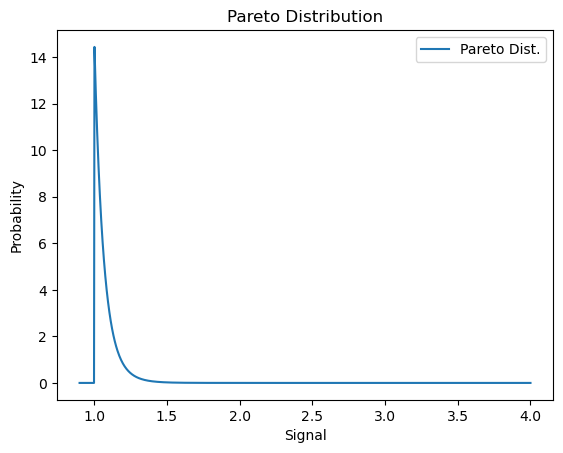

In [31]:
# Pareto Distribution
x_par = np.linspace(0.9,4,1000)
pareto = stats.pareto.pdf(x_par, 15)

fig, ax = plt.subplots()
ax.plot(x_par, pareto, label = 'Pareto Dist.')
ax.set_title('Pareto Distribution')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')
ax.legend()

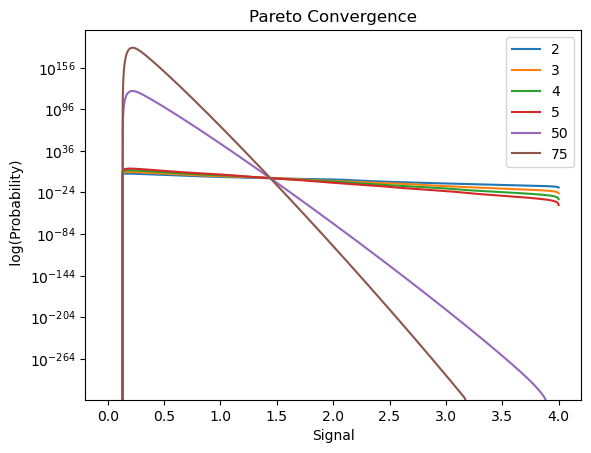

In [33]:
# Test Gaussian convergence
xp2, par2 = ave_interval(2, pareto, x_par)
xp3, par3 = ave_interval(3, pareto, x_par)
xp4, par4 = ave_interval(4, pareto, x_par)
xp5, par5 = ave_interval(5, pareto, x_par)
xp50, par50 = ave_interval(50, pareto, x_par)
xp75, par75 = ave_interval(75, pareto, x_par)
fig, ax = plt.subplots()

ax.plot(xp2, par2, label = '2')
ax.plot(xp3, par3,label = '3')
ax.plot(xp4, par4, label = '4')
ax.plot(xp5, par5, label = '5')
ax.plot(xp50, par50, label = '50')
ax.plot(xp75, par75, label = '75')
ax.set_title('Pareto Convergence')
ax.set_ylabel(' log(Probability)')
ax.set_xlabel('Signal')
ax.legend()
ax.legend()
ax.set_yscale('log')
# ax.plot(xp50, par50)

#### B) Discuss how the shape changes. Does it approach a Gaussian distribution? If yes, after how many intervals?

After increasing intervals, the distribution becomes much narrower and taller focused on the average value. In log space it goes from having a sharp point to being more smooth, however it does not seem to approach a Gaussian distribution as the plot in log space is still not parabolic. 

## Problem 3

We're going to explore one of the analysis questions that comes up when looking for the optical counterparts (a new optical source) of a gravity wave signal. For this problem let's assume that we are using an optical telescope with a thermal noise background from the CCD (dark current, particularly an issue with older CCDs and/or infra-red CCDs). After flat-fielding, the background appears as a zero-mean Gaussian with constant width over the image.

### Version 1

You have an alert from LIGO that is also seen in with the X-ray/ultra-violet satellite SWIFT. SWIFT gives you a very precise location, so you take an image of that part of the sky. But because of SWIFT's accuracy, you know which pixel in your image to look for a counterpart in.

#### A) From looking at all the other pixels in your image, you can measure the width of the background Gaussian distribution X (pick something). Assuming you see a signal of strength Y (pick a floating-point number; typical optical CCDs are not sensitive enough to count photons so the readings are floating point brightnesses, not integer photons). Calculate the significance of your detection. Can you claim a discovery (traditionally 5-sigma or more)?

Text(0.5, 0, 'Signal')

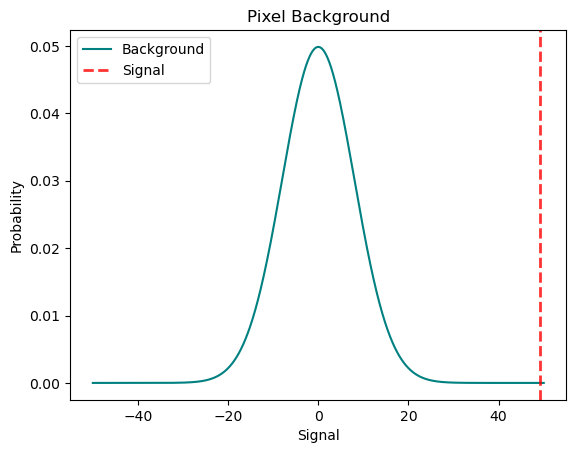

In [34]:
# Choose X = 8, Y = 49.2
x_pix = np.linspace(-50,50, 1000)
pixel_dist = stats.norm.pdf(x_pix, loc = 0, scale = 8)

fig, ax = plt.subplots()

ax.plot(x_pix, pixel_dist, color = 'teal', label = 'Background')
ax.axvline(49.2, alpha = 0.8, linestyle = '--', color = 'red', linewidth = 2, label = 'Signal')
ax.legend()
ax.set_title('Pixel Background')
ax.set_ylabel('Probability')
ax.set_xlabel('Signal')

In [16]:
# Find the probability and sigma
p_pix = stats.norm.sf(49.2, scale = 8)
sigma_pix = stats.norm.isf(p_pix)

print(f'The significance of the detection has a sigma of {sigma_pix:.2f}')

The significance of the detection has a sigma of 6.15


With a significance of 6.15 sigma, you could claim a discovery!

### Version 2

You have an alert from LIGO, but no associated detection from SWIFT. This could be because it is a black hole-black hole merger, a black hole-neutron star merger (neither seem to emit X-rays or UV light), or it could because SWIFT was indisposed at the time (wrong side of the earth in its orbit). Whatever the cause, you know what region of the sky to look in, but not which pixel.

#### B) If you have to look for a signal in 10k pixels, what is the probability distribution of your background? (Clearly state the statistical question, then turn that into math using your background distribution from part 1 of this problem.

**Statistical Question:** What is the probability distribution of the background of a 10k pixel detector given a zero mean Gaussian distribution with measured width for a single pixel?

In [17]:
pix_10k = pixel_dist*10000

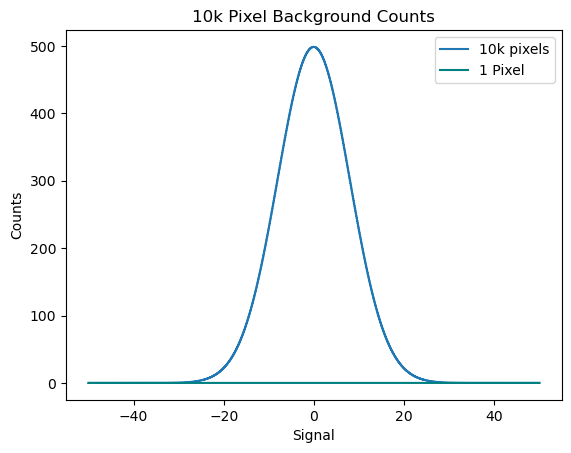

In [39]:
# plt.plot(x_pix, pixel_dist, label = '1 pixel')
fig, ax = plt.subplots()

ax.step(x_pix, pix_10k, label = '10k pixels')

ax.set_title('10k Pixel Background Counts')
ax.plot(x_pix, pixel_dist, color = 'teal', label = '1 Pixel')
ax.set_ylabel('Counts')
ax.set_xlabel('Signal')
ax.legend()

#### C) Taking your brightest candidate signal from the region (assume it has the same signal as in part 1), calculate the significance of your detection.

In [19]:
p_pix = stats.norm.sf(49.2, scale = 8)
sigma_pix = stats.norm.isf(p_pix*10000)

print(f'The significance of the detection has a sigma of {sigma_pix:.2f}')

The significance of the detection has a sigma of 4.47


## Problem 4

The statistical issue we were exploring in the previous problem is called a trials factor (sometimes known as a look-elsewhere effect). This is an important effect, as if you search through a million locations, you would expect to see approximately 1 one-in-a-million event. However, it is also often over estimated how big an impact this makes on the sensitivity of a search. So in this part of the lab we are going to invert the problem.

Let us again assume we have a Gaussian background (same parameters as Problem 3).

#### A) Calculate the signal required for a 5-sigma detection in Version 1

In [20]:
# 5 sigma prob:
prob_5s = stats.norm.sf(5)
sig_v1 = stats.norm.isf(prob_5s, scale = 8)
sig_v1

np.float64(40.00000000000001)

#### B) Calculate the signal required for a 5-sigma detection in Version 2

In [21]:
sig_v2 = stats.norm.isf(prob_5s/10000, scale = 8)
sig_v2

np.float64(52.40430090164267)

#### C) Discuss how much brighter the signal must be for discoverey if you have a trials factor of 10k. Looking at your probability distributions, explain why the sensitivity penalty due to a trials factor is so low.

In [22]:
sig_v2/sig_v1

np.float64(1.3101075225410665)

The signal must be brighter only by a factor of 1.3 for 10k trials, which is fairly low. This is likely because each pixel on the CCD is not necessarily an independent observation. Objects on the sky that affect multiple pixels cause correlations, an image with an entire CCD is not equivalent to taking a single pixel image 10k times. 

#### D) If you changed the trials factor significantly (orders of magnitude), how large is the effect on your 5-sigma sensitivity threshold?

In [23]:
sig_v3 = stats.norm.isf(prob_5s/(10**9), scale = 8)
sig_v3/sig_v1

np.float64(1.6189719724434184)

Changing the trial factor by a factor of 10^9 raises the sensitivity penalty by 0.3, larger, but not considerable so. 

#### Extra credit: If you had a different distribution shape (non-Gaussian), how would that affect the sensitivity penalty of many trials? Clearly explain.

Text(0.5, 1.0, 'Sensativity Penalty Comparison')

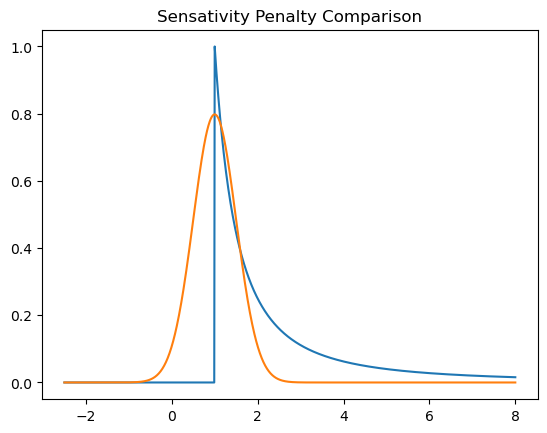

In [57]:
x_sens = np.linspace(-2.5,8,1000)
pareto_sens = stats.pareto.pdf(x_sens, 1)
gauss_sens = stats.norm.pdf(x_sens, loc = 1, scale = 0.5)

fig, ax = plt.subplots()
ax.plot(x_sens, pareto_sens)
ax.plot(x_sens, gauss_sens)

ax.set_title('Sensativity Penalty Comparison')

Comparing a Gaussian distribution to a non Gaussian distribution like the Pareto Distribution from above, we can see that the edge behavior influences the sensativity penalty. For the Gaussian distribution, observations can become high sigma/low probability once you begin to move into the tail region. This low probability is what allows the multiple trial scaling to be applied directly because the probability still remains small even after a large trial number.

However for non-Gaussian distributions like the Pareto which decay slowly, the signal needed to have low probability becomes much higher, so a signal which has a low sensativity penalty in a Gaussian distribution can have the sensativity blown up in a Pareto(or other slowly decaying) distribution. 